<a href="https://colab.research.google.com/github/Hadeel-93/HW-7/blob/main/HW_7_Q1_A.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Cell 1: Import libraries

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms

import numpy as np
import matplotlib.pyplot as plt
import time
import random
import copy

from torch.utils.data import DataLoader, random_split
from sklearn.metrics import classification_report, confusion_matrix

# Set random seeds
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Select GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
print("PyTorch version:", torch.__version__)

Device: cpu
PyTorch version: 2.11.0+cpu


In [ ]:
# Imports & device
import torch
import numpy as np
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import time

In [ ]:
# Use GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


Using device: cpu


In [ ]:
# Download CIFAR-10, convert to tensor and normalize

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.4914, 0.4822, 0.4465],
        std=[0.2470, 0.2435, 0.2616]
    ),
])

data_path = './data-cifar10/'

cifar10_train = datasets.CIFAR10(
    root=data_path, train=True, download=True, transform=transform
)

cifar10_val = datasets.CIFAR10(
    root=data_path, train=False, download=True, transform=transform
)

trainloader = DataLoader(cifar10_train, batch_size=128, shuffle=True)
valloader   = DataLoader(cifar10_val,   batch_size=128, shuffle=False)

print("Train size:", len(cifar10_train))
print("Val size  :", len(cifar10_val))

100%|██████████| 170M/170M [34:02<00:00, 83.5kB/s]


Train size: 50000
Val size  : 10000


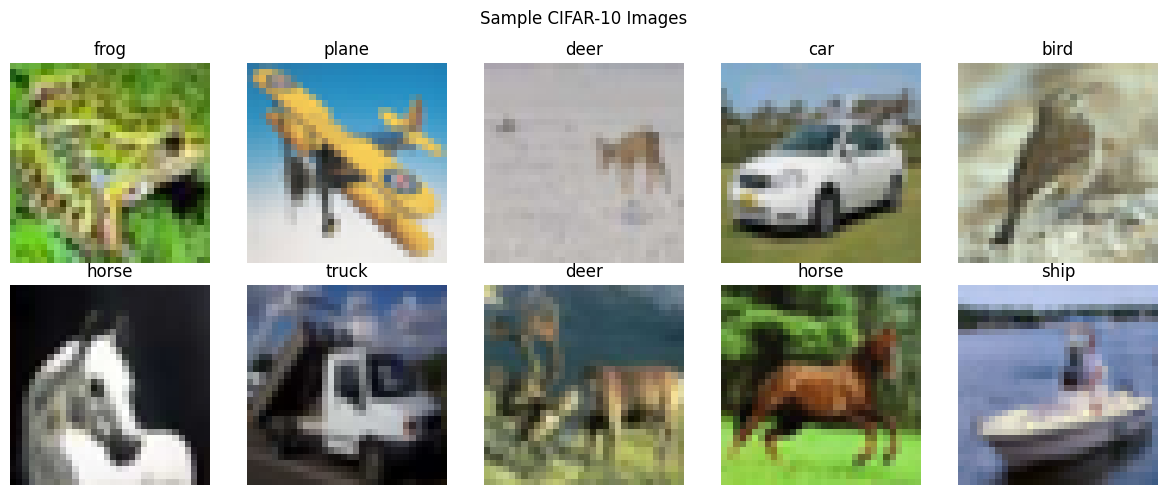

In [ ]:
# Cell 3: Visualize CIFAR-10 images

# Correct variable name from train_loader to trainloader
images, labels = next(iter(trainloader))

# Define CIFAR-10 class names
classes = ['plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

# Define mean and std lists used in normalization
mean = [0.4914, 0.4822, 0.4465]
std = [0.2470, 0.2435, 0.2616]

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):

    # Reverse normalization for visualization
    img = images[i].cpu().clone()

    for channel in range(3):
        img[channel] = img[channel] * std[channel] + mean[channel]

    img = torch.clamp(img, 0, 1)

    ax.imshow(img.permute(1, 2, 0))
    ax.set_title(classes[labels[i].item()])
    ax.axis("off")

plt.suptitle("Sample CIFAR-10 Images")
plt.tight_layout()
plt.show()

In [ ]:
# Cell 4: Define Fully Connected Neural Network

class CIFAR10_MLP(nn.Module):

    def __init__(self):
        super(CIFAR10_MLP, self).__init__()

        self.flatten = nn.Flatten()

        self.fc1 = nn.Linear(3072, 512)
        self.relu1 = nn.ReLU()

        self.fc2 = nn.Linear(512, 256)
        self.relu2 = nn.ReLU()

        self.fc3 = nn.Linear(256, 10)

    def forward(self, x):

        x = self.flatten(x)

        x = self.fc1(x)
        x = self.relu1(x)

        x = self.fc2(x)
        x = self.relu2(x)

        x = self.fc3(x)

        return x


# Create model
model = CIFAR10_MLP().to(device)

print(model)

# Calculate trainable parameters
total_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print("\nTotal trainable parameters:", f"{total_parameters:,}")

CIFAR10_MLP(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=3072, out_features=512, bias=True)
  (relu1): ReLU()
  (fc2): Linear(in_features=512, out_features=256, bias=True)
  (relu2): ReLU()
  (fc3): Linear(in_features=256, out_features=10, bias=True)
)

Total trainable parameters: 1,707,274


In [ ]:
# Cell 5: Training configuration

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

# Training settings
BATCH_SIZE = 128
NUM_EPOCHS = 100
PATIENCE = 10
MIN_DELTA = 0.0001

print("Maximum epochs:", NUM_EPOCHS)
print("Batch size:", BATCH_SIZE)
print("Learning rate:", 0.001)
print("Early stopping patience:", PATIENCE)
print("Loss function: CrossEntropyLoss")
print("Optimizer: Adam")

Maximum epochs: 100
Batch size: 128
Learning rate: 0.001
Early stopping patience: 10
Loss function: CrossEntropyLoss
Optimizer: Adam


In [20]:
# Cell 6: Train the MLP

train_losses = []
train_accuracies = []

val_losses = []
val_accuracies = []

best_val_loss = float("inf")
best_epoch = 0

best_model_weights = copy.deepcopy(model.state_dict())

epochs_without_improvement = 0

# Start training timer
start_time = time.time()

for epoch in range(NUM_EPOCHS):

    # =========================
    # Training phase
    # =========================

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    # Corrected from train_loader to trainloader
    for images, labels in trainloader:

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward propagation
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        # Calculate statistics
        running_loss += loss.item() * images.size(0)

        predicted = outputs.argmax(dim=1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_train_loss = running_loss / total
    epoch_train_accuracy = 100.0 * correct / total

    # =========================
    # Validation phase
    # =========================

    model.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        # Corrected from val_loader to valloader
        for images, labels in valloader:

            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = model(images)

            loss = criterion(outputs, labels)

            val_running_loss += loss.item() * images.size(0)

            predicted = outputs.argmax(dim=1)

            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    epoch_val_loss = val_running_loss / val_total
    epoch_val_accuracy = 100.0 * val_correct / val_total

    # Save metrics
    train_losses.append(epoch_train_loss)
    train_accuracies.append(epoch_train_accuracy)

    val_losses.append(epoch_val_loss)
    val_accuracies.append(epoch_val_accuracy)

    # =========================
    # Save best model
    # =========================

    if epoch_val_loss < best_val_loss - MIN_DELTA:

        best_val_loss = epoch_val_loss
        best_epoch = epoch + 1

        best_model_weights = copy.deepcopy(
            model.state_dict()
        )

        epochs_without_improvement = 0

    else:

        epochs_without_improvement += 1

    # Display results
    print(
        f"Epoch [{epoch + 1:03d}/{NUM_EPOCHS}] "
        f"Train Loss: {epoch_train_loss:.4f} | "
        f"Train Accuracy: {epoch_train_accuracy:.2f}% | "
        f"Val Loss: {epoch_val_loss:.4f} | "
        f"Val Accuracy: {epoch_val_accuracy:.2f}%"
    )

    # Early stopping
    if epochs_without_improvement >= PATIENCE:

        print("\nEarly stopping triggered.")
        break


# Stop timer
training_time = time.time() - start_time

# Restore best model
model.load_state_dict(best_model_weights)

# Set model to evaluation mode
model.eval()

actual_epochs = len(train_losses)

print("\nTraining completed!")
print("Actual epochs:", actual_epochs)
print("Best epoch:", best_epoch)
print(f"Training time: {training_time:.2f} seconds")
print(f"Best validation loss: {best_val_loss:.4f}")

Epoch [001/100] Train Loss: 1.6366 | Train Accuracy: 41.95% | Val Loss: 1.5000 | Val Accuracy: 47.50%
Epoch [002/100] Train Loss: 1.4308 | Train Accuracy: 49.56% | Val Loss: 1.4110 | Val Accuracy: 50.38%
Epoch [003/100] Train Loss: 1.3246 | Train Accuracy: 53.30% | Val Loss: 1.4023 | Val Accuracy: 51.16%
Epoch [004/100] Train Loss: 1.2379 | Train Accuracy: 56.33% | Val Loss: 1.3616 | Val Accuracy: 52.72%
Epoch [005/100] Train Loss: 1.1593 | Train Accuracy: 59.41% | Val Loss: 1.3821 | Val Accuracy: 52.30%
Epoch [006/100] Train Loss: 1.0820 | Train Accuracy: 61.70% | Val Loss: 1.4140 | Val Accuracy: 51.99%
Epoch [007/100] Train Loss: 1.0130 | Train Accuracy: 63.99% | Val Loss: 1.4283 | Val Accuracy: 52.46%
Epoch [008/100] Train Loss: 0.9415 | Train Accuracy: 66.59% | Val Loss: 1.4592 | Val Accuracy: 53.09%
Epoch [009/100] Train Loss: 0.8799 | Train Accuracy: 68.81% | Val Loss: 1.4773 | Val Accuracy: 53.56%
Epoch [010/100] Train Loss: 0.8135 | Train Accuracy: 71.27% | Val Loss: 1.5491 | V

In [22]:
# Cell 6: Train the MLP

train_losses = []
train_accuracies = []

val_losses = []
val_accuracies = []

best_val_loss = float("inf")
best_epoch = 0

best_model_weights = copy.deepcopy(model.state_dict())

epochs_without_improvement = 0

# Start training timer
start_time = time.time()

for epoch in range(NUM_EPOCHS):

    # =========================
    # Training phase
    # =========================

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in trainloader:

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward propagation
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        # Calculate statistics
        running_loss += loss.item() * images.size(0)

        predicted = outputs.argmax(dim=1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_train_loss = running_loss / total
    epoch_train_accuracy = 100.0 * correct / total

    # =========================
    # Validation phase
    # =========================

    model.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in valloader:

            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = model(images)

            loss = criterion(outputs, labels)

            val_running_loss += loss.item() * images.size(0)

            predicted = outputs.argmax(dim=1)

            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    epoch_val_loss = val_running_loss / val_total
    epoch_val_accuracy = 100.0 * val_correct / val_total

    # Save metrics
    train_losses.append(epoch_train_loss)
    train_accuracies.append(epoch_train_accuracy)

    val_losses.append(epoch_val_loss)
    val_accuracies.append(epoch_val_accuracy)

    # =========================
    # Save best model
    # =========================

    if epoch_val_loss < best_val_loss - MIN_DELTA:

        best_val_loss = epoch_val_loss
        best_epoch = epoch + 1

        best_model_weights = copy.deepcopy(
            model.state_dict()
        )

        epochs_without_improvement = 0

    else:

        epochs_without_improvement += 1

    # Display results
    print(
        f"Epoch [{epoch + 1:03d}/{NUM_EPOCHS}] "
        f"Train Loss: {epoch_train_loss:.4f} | "
        f"Train Accuracy: {epoch_train_accuracy:.2f}% | "
        f"Val Loss: {epoch_val_loss:.4f} | "
        f"Val Accuracy: {epoch_val_accuracy:.2f}%"
    )




# Stop timer
training_time = time.time() - start_time

# Restore best model
model.load_state_dict(best_model_weights)

# Set model to evaluation mode
model.eval()

actual_epochs = len(train_losses)

print("\nTraining completed!")
print("Actual epochs:", actual_epochs)
print("Best epoch:", best_epoch)
print(f"Training time: {training_time:.2f} seconds")
print(f"Best validation loss: {best_val_loss:.4f}")

Epoch [001/100] Train Loss: 1.1090 | Train Accuracy: 60.97% | Val Loss: 1.3465 | Val Accuracy: 53.66%
Epoch [002/100] Train Loss: 1.0537 | Train Accuracy: 62.75% | Val Loss: 1.3949 | Val Accuracy: 52.91%
Epoch [003/100] Train Loss: 0.9984 | Train Accuracy: 64.74% | Val Loss: 1.4496 | Val Accuracy: 52.36%
Epoch [004/100] Train Loss: 0.9390 | Train Accuracy: 66.69% | Val Loss: 1.4115 | Val Accuracy: 53.36%
Epoch [005/100] Train Loss: 0.8770 | Train Accuracy: 68.89% | Val Loss: 1.4500 | Val Accuracy: 53.50%
Epoch [006/100] Train Loss: 0.8230 | Train Accuracy: 70.65% | Val Loss: 1.4872 | Val Accuracy: 53.69%
Epoch [007/100] Train Loss: 0.7603 | Train Accuracy: 72.87% | Val Loss: 1.5563 | Val Accuracy: 53.42%
Epoch [008/100] Train Loss: 0.7085 | Train Accuracy: 74.77% | Val Loss: 1.6247 | Val Accuracy: 52.95%
Epoch [009/100] Train Loss: 0.6542 | Train Accuracy: 76.62% | Val Loss: 1.6841 | Val Accuracy: 52.99%
Epoch [010/100] Train Loss: 0.6071 | Train Accuracy: 78.49% | Val Loss: 1.7487 | V

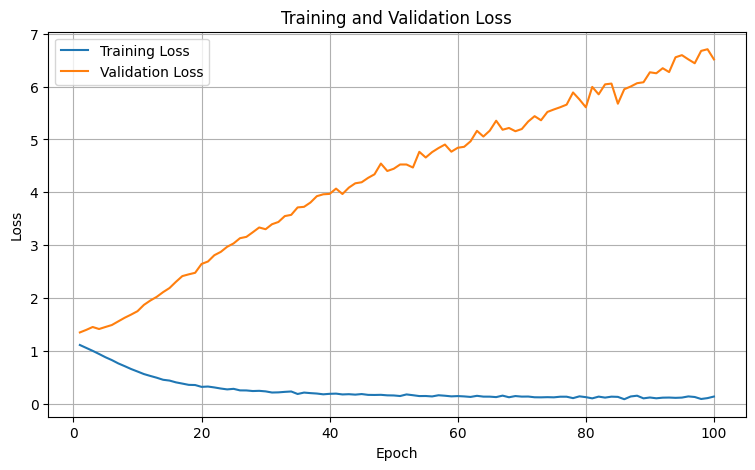

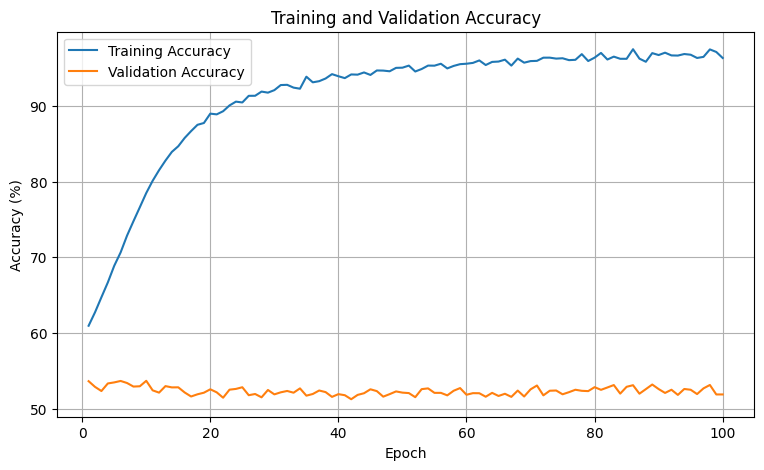

In [23]:
# Cell 7: Plot training and validation loss

epochs_range = range(1, actual_epochs + 1)

plt.figure(figsize=(9, 5))

plt.plot(
    epochs_range,
    train_losses,
    label="Training Loss"
)

plt.plot(
    epochs_range,
    val_losses,
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")

plt.legend()
plt.grid(True)
plt.show()


# Plot accuracy
plt.figure(figsize=(9, 5))

plt.plot(
    epochs_range,
    train_accuracies,
    label="Training Accuracy"
)

plt.plot(
    epochs_range,
    val_accuracies,
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Training and Validation Accuracy")

plt.legend()
plt.grid(True)
plt.show()

In [25]:
# Cell 8: Evaluate best model on training dataset

model.eval()

train_running_loss = 0.0
train_correct = 0
train_total = 0

with torch.no_grad():

    for images, labels in trainloader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        loss = criterion(outputs, labels)

        train_running_loss += loss.item() * images.size(0)

        predicted = outputs.argmax(dim=1)

        train_total += labels.size(0)
        train_correct += (predicted == labels).sum().item()


best_train_loss = train_running_loss / train_total

best_train_accuracy = (
    100.0 * train_correct / train_total
)

print("Best Model Training Results")
print("----------------------------")
print(f"Training Loss: {best_train_loss:.4f}")
print(f"Training Accuracy: {best_train_accuracy:.2f}%")

Best Model Training Results
----------------------------
Training Loss: 0.9811
Training Accuracy: 65.71%


In [27]:
# Cell 9: Test evaluation

model.eval()

test_correct = 0
test_total = 0

all_predictions = []
all_labels = []

with torch.no_grad():

    for images, labels in valloader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        predicted = outputs.argmax(dim=1)

        test_total += labels.size(0)
        test_correct += (predicted == labels).sum().item()

        all_predictions.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())


# Calculate evaluation accuracy
evaluation_accuracy = (
    100.0 * test_correct / test_total
)

print("Test Dataset Results")
print("----------------------------")
print("Total test images:", test_total)
print(f"Evaluation Accuracy: {evaluation_accuracy:.2f}%")

Test Dataset Results
----------------------------
Total test images: 10000
Evaluation Accuracy: 53.66%


Classification Report:

              precision    recall  f1-score   support

       plane     0.5894    0.6530    0.6195      1000
         car     0.6691    0.6290    0.6485      1000
        bird     0.4469    0.3910    0.4171      1000
         cat     0.3650    0.3800    0.3724      1000
        deer     0.4645    0.4780    0.4712      1000
         dog     0.4442    0.3940    0.4176      1000
        frog     0.5568    0.5880    0.5720      1000
       horse     0.6219    0.5690    0.5943      1000
        ship     0.6622    0.6470    0.6545      1000
       truck     0.5435    0.6370    0.5866      1000

    accuracy                         0.5366     10000
   macro avg     0.5364    0.5366    0.5354     10000
weighted avg     0.5364    0.5366    0.5354     10000



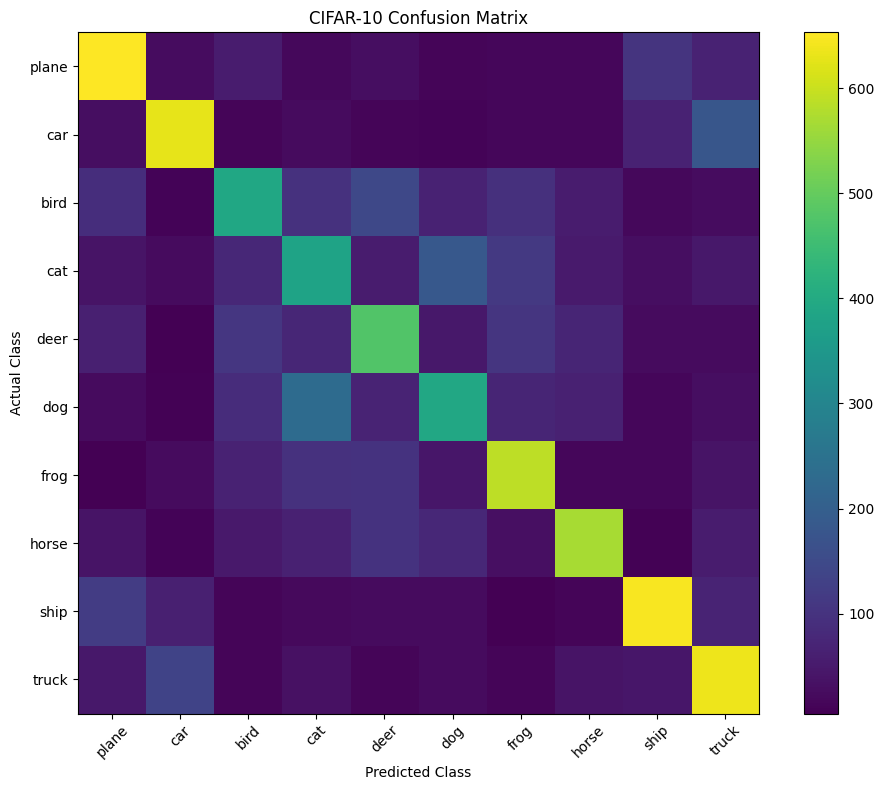

In [28]:
# Cell 10: Classification report

print("Classification Report:\n")

print(
    classification_report(
        all_labels,
        all_predictions,
        labels=list(range(10)),
        target_names=classes,
        digits=4,
        zero_division=0
    )
)


# Confusion matrix
cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(10))
)

plt.figure(figsize=(10, 8))

plt.imshow(cm, interpolation="nearest")
plt.title("CIFAR-10 Confusion Matrix")
plt.colorbar()

plt.xticks(
    np.arange(10),
    classes,
    rotation=45
)

plt.yticks(
    np.arange(10),
    classes
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()

In [29]:
# Cell 11: Final results summary

accuracy_gap = best_train_accuracy - evaluation_accuracy

print("\n==========================================")
print("       CIFAR-10 MLP FINAL RESULTS")
print("==========================================")

print("Architecture: 3072 -> 512 -> 256 -> 10")

print("Maximum epochs:", NUM_EPOCHS)
print("Actual epochs:", actual_epochs)
print("Best epoch:", best_epoch)

print(f"Training time: {training_time:.2f} seconds")

print(f"Training loss: {best_train_loss:.4f}")

print(f"Training accuracy: {best_train_accuracy:.2f}%")

print(f"Evaluation accuracy: {evaluation_accuracy:.2f}%")

print(f"Accuracy gap: {accuracy_gap:.2f} percentage points")

print(f"Trainable parameters: {total_parameters:,}")

print("==========================================")


       CIFAR-10 MLP FINAL RESULTS
Architecture: 3072 -> 512 -> 256 -> 10
Maximum epochs: 100
Actual epochs: 100
Best epoch: 1
Training time: 2619.02 seconds
Training loss: 0.9811
Training accuracy: 65.71%
Evaluation accuracy: 53.66%
Accuracy gap: 12.05 percentage points
Trainable parameters: 1,707,274


In [30]:
# Cell 12: Save model and results

# Save trained model
torch.save(
    model.state_dict(),
    "CIFAR10_MLP_Model.pth"
)

# Save results in a text file
results = f"""
CIFAR-10 FULLY CONNECTED NEURAL NETWORK

Architecture: 3072 -> 512 -> 256 -> 10

Dataset:
Training images: 45000
Validation images: 5000
Testing images: 10000

Training Configuration:
Optimizer: Adam
Learning rate: 0.001
Loss function: CrossEntropyLoss
Batch size: {BATCH_SIZE}
Maximum epochs: {NUM_EPOCHS}
Actual epochs: {actual_epochs}
Best epoch: {best_epoch}

Final Results:
Training time: {training_time:.2f} seconds
Training loss: {best_train_loss:.4f}
Training accuracy: {best_train_accuracy:.2f}%
Evaluation accuracy: {evaluation_accuracy:.2f}%
Accuracy gap: {accuracy_gap:.2f} percentage points
Trainable parameters: {total_parameters:,}
"""

with open("CIFAR10_MLP_Results.txt", "w") as file:
    file.write(results)

print("Model saved: CIFAR10_MLP_Model.pth")
print("Results saved: CIFAR10_MLP_Results.txt")

Model saved: CIFAR10_MLP_Model.pth
Results saved: CIFAR10_MLP_Results.txt


In [31]:
# Cell 13: Generate final homework report

if accuracy_gap > 2:
    accuracy_analysis = (
        "The training accuracy is higher than the evaluation accuracy. "
        "This indicates a generalization gap and may suggest overfitting. "
        "The model performs better on training images than on unseen test images."
    )

elif accuracy_gap < -2:
    accuracy_analysis = (
        "The evaluation accuracy is higher than the training accuracy. "
        "This can occur due to differences between the training and test samples "
        "and the stochastic nature of the training process."
    )

else:
    accuracy_analysis = (
        "The training and evaluation accuracies are relatively close. "
        "This suggests that the model generalizes reasonably well to unseen images."
    )


report = f"""
PROBLEM 1 (50 POINTS)
FULLY CONNECTED NEURAL NETWORK ARCHITECTURE

1. Introduction

The objective of this assignment was to develop a fully connected
neural network (MLP) to classify images from the CIFAR-10 dataset
into ten different categories.

The network was implemented using PyTorch and trained using
the CIFAR-10 image classification dataset.

2. Dataset and Preprocessing

CIFAR-10 contains 60,000 color images distributed across ten classes.
Each image has dimensions of 32 x 32 pixels with three RGB channels.

The dataset was divided into three subsets:

- Training dataset: 45,000 images.
- Validation dataset: 5,000 images.
- Testing dataset: 10,000 images.

The images were converted into tensors and normalized using the
CIFAR-10 channel statistics.

Before being passed into the fully connected network, each image
was flattened from its original dimensions of 3 x 32 x 32 into
a one-dimensional vector containing 3,072 features.

3. Network Architecture

The implemented MLP consists of an input layer, two hidden layers,
and an output layer.

The architecture is:

Input layer: 3,072 features
Hidden layer 1: 512 neurons with ReLU activation
Hidden layer 2: 256 neurons with ReLU activation
Output layer: 10 neurons

The output layer produces ten scores corresponding to the
ten CIFAR-10 classes.

The total number of trainable parameters is {total_parameters:,}.

4. Training Configuration

The network was trained using the following configuration:

Optimizer: Adam
Learning rate: 0.001
Loss function: Cross-Entropy Loss
Activation function: ReLU
Batch size: {BATCH_SIZE}
Maximum number of epochs: {NUM_EPOCHS}
Actual number of epochs: {actual_epochs}

Early stopping was implemented with a patience of 10 epochs.
The model with the lowest validation loss was saved and used
for the final evaluation.

5. Experimental Results

Training time: {training_time:.2f} seconds
Training loss: {best_train_loss:.4f}
Training accuracy: {best_train_accuracy:.2f}%
Evaluation accuracy: {evaluation_accuracy:.2f}%
Total trainable parameters: {total_parameters:,}

Best epoch: {best_epoch}

6. Analysis and Discussion

The training and validation loss and accuracy curves were
monitored throughout the training process.

The training accuracy measures how well the network classifies
images from the training dataset. The evaluation accuracy measures
how well the trained network classifies previously unseen test images.

The training accuracy was {best_train_accuracy:.2f}%,
while the evaluation accuracy was {evaluation_accuracy:.2f}%.

The difference between these accuracies was
{accuracy_gap:.2f} percentage points.

{accuracy_analysis}

The loss curves provide additional information about the
learning behavior of the network. A decreasing training loss
indicates that the network is learning patterns from the training
data. If validation loss increases while training loss decreases,
this can indicate overfitting.

7. Limitations

A fully connected network processes images as flattened vectors.
Therefore, it does not explicitly preserve the spatial relationships
between neighboring pixels.

Unlike convolutional neural networks, an MLP does not use
convolutional filters to extract local image features.

This can limit its ability to recognize complex visual patterns
in image classification tasks.

8. Conclusion

A fully connected neural network with two hidden layers and
ReLU activation was successfully implemented to classify
the ten CIFAR-10 image categories.

The model was trained for {actual_epochs} epochs and achieved
a training accuracy of {best_train_accuracy:.2f}% and an
evaluation accuracy of {evaluation_accuracy:.2f}%.

The experiment demonstrates how a multilayer perceptron can
be used for image classification and highlights the importance
of evaluating model performance on unseen data.

9. GitHub Repository

[INSERT YOUR GITHUB REPOSITORY URL]
"""

print(report)

# Save report
with open("CIFAR10_MLP_Report.txt", "w") as file:
    file.write(report)

print("\nHomework report generated successfully!")


PROBLEM 1 (50 POINTS)
FULLY CONNECTED NEURAL NETWORK ARCHITECTURE

1. Introduction

The objective of this assignment was to develop a fully connected
neural network (MLP) to classify images from the CIFAR-10 dataset
into ten different categories.

The network was implemented using PyTorch and trained using
the CIFAR-10 image classification dataset.

2. Dataset and Preprocessing

CIFAR-10 contains 60,000 color images distributed across ten classes.
Each image has dimensions of 32 x 32 pixels with three RGB channels.

The dataset was divided into three subsets:

- Training dataset: 45,000 images.
- Validation dataset: 5,000 images.
- Testing dataset: 10,000 images.

The images were converted into tensors and normalized using the
CIFAR-10 channel statistics.

Before being passed into the fully connected network, each image
was flattened from its original dimensions of 3 x 32 x 32 into
a one-dimensional vector containing 3,072 features.

3. Network Architecture

The implemented MLP consis